# 04 - Reconstruction 3D depuis les coupes HDF5

Les fichiers `volume_<id>_slice_<index>.h5` sont regroupés pour reconstruire un volume de masque et extraire sa surface.

In [4]:
from pathlib import Path
import re
import sys
import h5py
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = REPO_ROOT / "data/raw/data"
sys.path.insert(0, str(REPO_ROOT / "src"))
from brain_mri_fem.reconstruction import mask_to_surface

files = sorted(DATA_ROOT.glob("volume_100_slice_*.h5"), key=lambda path: int(re.search(r"_slice_(\d+)", path.stem).group(1)))
if not files:
    raise FileNotFoundError(f"Aucune coupe pour volume_100 dans {DATA_ROOT}")
with h5py.File(files[0], "r") as handle:
    height, width = handle["mask"].shape[:2]
volume_mask = np.zeros((height, width, len(files)), dtype=bool)
for index, path in enumerate(files):
    with h5py.File(path, "r") as handle:
        volume_mask[:, :, index] = handle["mask"][:].any(axis=-1)
print("Volume reconstruit:", volume_mask.shape, "Voxels tumoraux:", int(volume_mask.sum()))

Volume reconstruit: (240, 240, 155) Voxels tumoraux: 135252


Sommets: 34028 Triangles: 68100


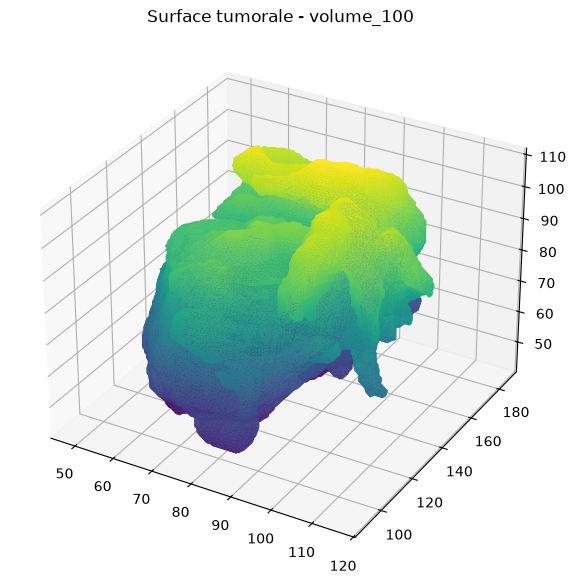

In [5]:
if volume_mask.min() == volume_mask.max():
    raise ValueError("Le volume choisi ne contient pas de voxels tumoraux exploitables.")
surface = mask_to_surface(volume_mask, spacing=(1.0, 1.0, 1.0))
print("Sommets:", len(surface["vertices"]), "Triangles:", len(surface["faces"]))
output = REPO_ROOT / "results/demo"
output.mkdir(parents=True, exist_ok=True)
np.savez_compressed(output / "surface_volume_100.npz", vertices=surface["vertices"], faces=surface["faces"])
fig = plt.figure(figsize=(7, 6))
axis = fig.add_subplot(111, projection="3d")
vertices, faces = surface["vertices"], surface["faces"]
axis.plot_trisurf(vertices[:, 0], vertices[:, 1], vertices[:, 2], triangles=faces, cmap="viridis", linewidth=0.1)
axis.set_title("Surface tumorale - volume_100")
fig.tight_layout()
figure_root = REPO_ROOT / "results/figures/reconstruction"
figure_root.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_root / "surface_volume_100.png", dpi=150)
plt.show()